
###EXPERIMENT NO. 10
###End-to-End Data Analytics Project:
###Business Intelligence and Predictive Analytics


###NAME       : Akshit Negi
###UID        : CU24250214
###COURSE     : BTECH CSE
###SECTION    : B
###ROLL NO.   : 04


###AIM
###To implement a complete data analytics workflow on a real-world dataset by performing data preprocessing, exploratory data analysis,
###statistical analysis, visualization, predictive modeling, and
###presentation of actionable business insights.



STEP 1: IMPORT LIBRARIES



In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk

from tkinter import filedialog

from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



STEP 2: SELECT DATASET


In [ ]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("No dataset selected.")

# Assuming only one file is uploaded, get its name
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

Saving Advertising Budget and Sales.csv to Advertising Budget and Sales.csv


STEP 3: DISPLAY BASIC DATASET INFORMATION


In [ ]:

print("Dataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nFirst Five Rows:")
print(df.head())

print("\nDataset Information:")
df.info()



Dataset Shape: (200, 5)

Dataset Columns:
['Unnamed: 0', 'TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)', 'Sales ($)']

First Five Rows:
   Unnamed: 0  TV Ad Budget ($)  Radio Ad Budget ($)  Newspaper Ad Budget ($)  \
0           1             230.1                 37.8                     69.2   
1           2              44.5                 39.3                     45.1   
2           3              17.2                 45.9                     69.3   
3           4             151.5                 41.3                     58.5   
4           5             180.8                 10.8                     58.4   

   Sales ($)  
0       22.1  
1       10.4  
2        9.3  
3       18.5  
4       12.9  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               2

STEP 4: DATA PREPROCESSING


In [ ]:

# Remove unnecessary index column if present
if "Unnamed: 0" in df.columns:
    df.drop("Unnamed: 0", axis=1, inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Convert required columns to numeric
numeric_columns = [
    "TV Ad Budget ($)",
    "Radio Ad Budget ($)",
    "Newspaper Ad Budget ($)",
    "Sales ($)"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Handle missing values
df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

print("\nMissing Values After Preprocessing:")
print(df.isnull().sum())

print("\nDuplicate Rows After Preprocessing:", df.duplicated().sum())




Missing Values After Preprocessing:
TV Ad Budget ($)           0
Radio Ad Budget ($)        0
Newspaper Ad Budget ($)    0
Sales ($)                  0
dtype: int64

Duplicate Rows After Preprocessing: 0


STEP 5: DESCRIPTIVE STATISTICS


In [ ]:

print("\nDescriptive Statistics:")
print(df.describe())




Descriptive Statistics:
       TV Ad Budget ($)  Radio Ad Budget ($)  Newspaper Ad Budget ($)  \
count        200.000000           200.000000               200.000000   
mean         147.042500            23.264000                30.554000   
std           85.854236            14.846809                21.778621   
min            0.700000             0.000000                 0.300000   
25%           74.375000             9.975000                12.750000   
50%          149.750000            22.900000                25.750000   
75%          218.825000            36.525000                45.100000   
max          296.400000            49.600000               114.000000   

        Sales ($)  
count  200.000000  
mean    14.022500  
std      5.217457  
min      1.600000  
25%     10.375000  
50%     12.900000  
75%     17.400000  
max     27.000000  


STEP 6: OUTLIER ANALYSIS


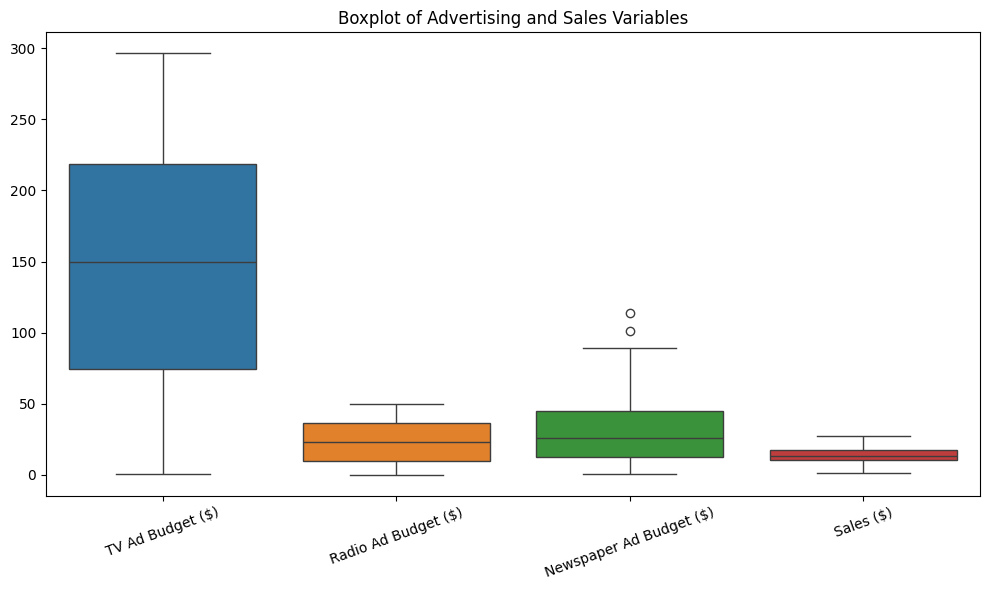

In [ ]:

plt.figure(figsize=(10, 6))

sns.boxplot(data=df)

plt.title("Boxplot of Advertising and Sales Variables")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



STEP 7: DISTRIBUTION ANALYSIS


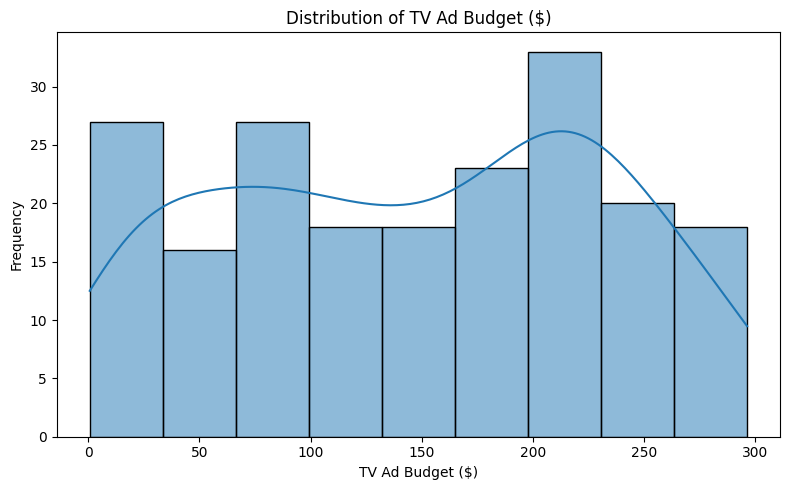

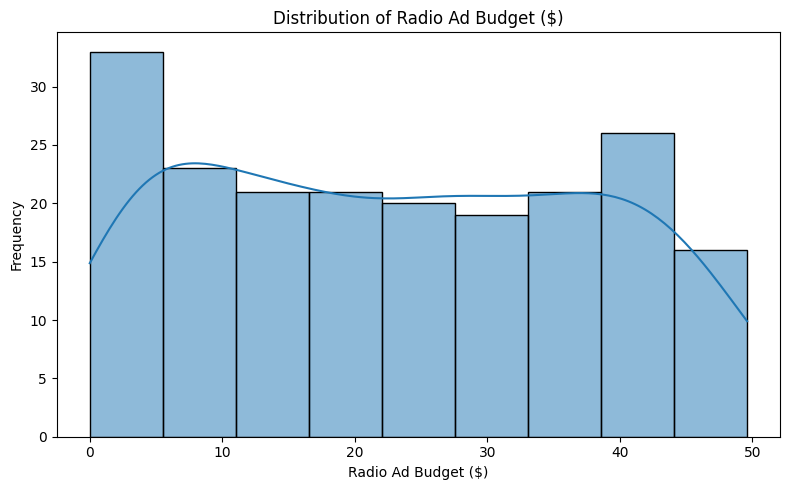

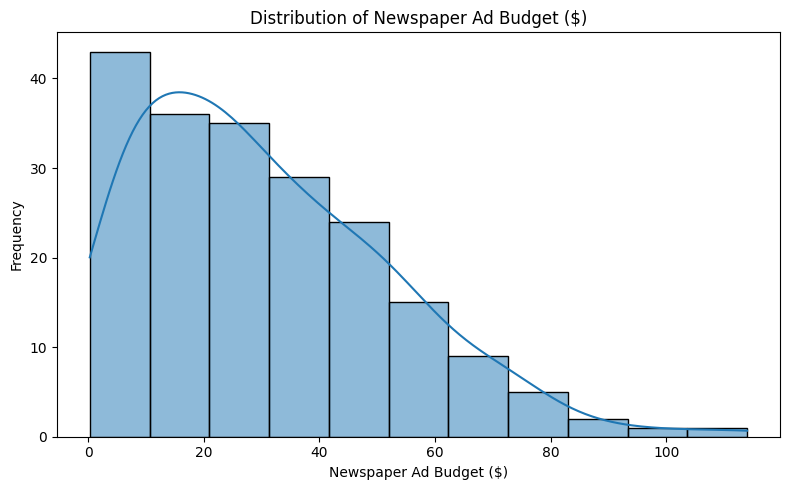

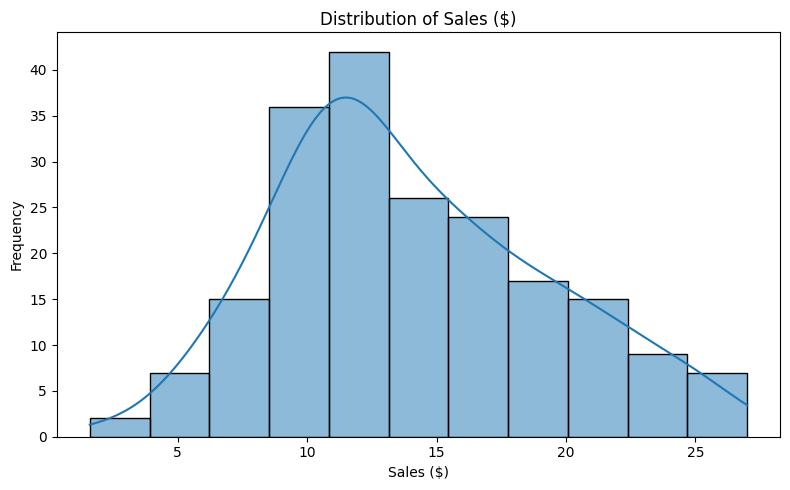

In [ ]:

for column in numeric_columns:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        df[column],
        kde=True
    )

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()



STEP 8: CORRELATION ANALYSIS



Correlation Matrix:
                         TV Ad Budget ($)  Radio Ad Budget ($)  \
TV Ad Budget ($)                 1.000000             0.054809   
Radio Ad Budget ($)              0.054809             1.000000   
Newspaper Ad Budget ($)          0.056648             0.354104   
Sales ($)                        0.782224             0.576223   

                         Newspaper Ad Budget ($)  Sales ($)  
TV Ad Budget ($)                        0.056648   0.782224  
Radio Ad Budget ($)                     0.354104   0.576223  
Newspaper Ad Budget ($)                 1.000000   0.228299  
Sales ($)                               0.228299   1.000000  


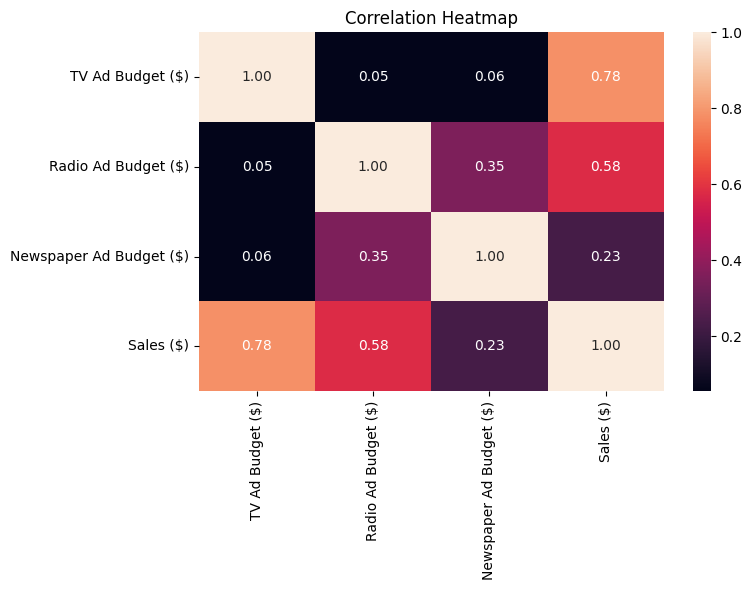

In [ ]:

correlation_matrix = df[numeric_columns].corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()



STEP 9: ADVERTISING BUDGET VS SALES


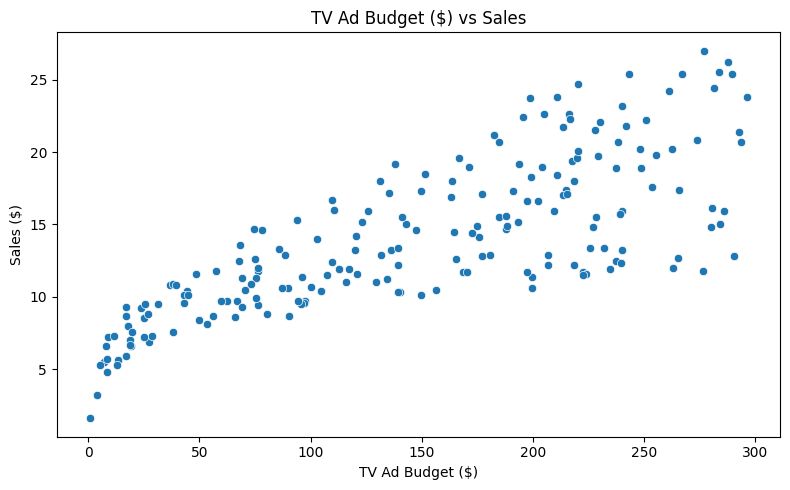

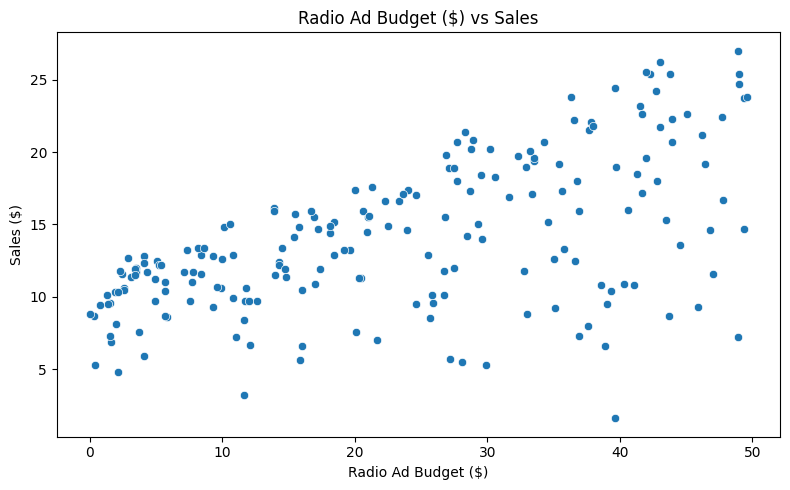

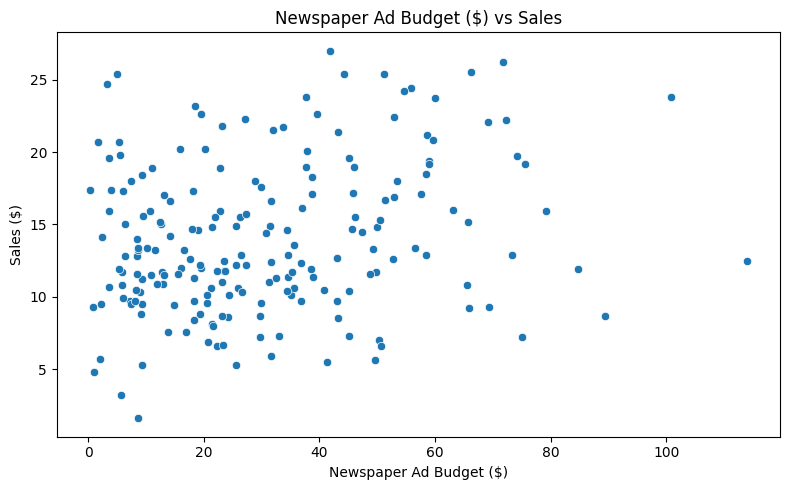

In [ ]:

advertising_columns = [
    "TV Ad Budget ($)",
    "Radio Ad Budget ($)",
    "Newspaper Ad Budget ($)"
]

for column in advertising_columns:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=column,
        y="Sales ($)"
    )

    plt.title(column + " vs Sales")
    plt.xlabel(column)
    plt.ylabel("Sales ($)")

    plt.tight_layout()
    plt.show()



STEP 10: STATISTICAL ANALYSIS


In [ ]:

print("\n========== PEARSON CORRELATION TEST ==========")

for column in advertising_columns:

    correlation, p_value = pearsonr(
        df[column],
        df["Sales ($)"]
    )

    print("\n", column)
    print("Correlation:", round(correlation, 4))
    print("P-value:", round(p_value, 6))




========== PEARSON CORRELATION TEST ==========

 TV Ad Budget ($)
Correlation: 0.7822
P-value: 0.0

 Radio Ad Budget ($)
Correlation: 0.5762
P-value: 0.0

 Newspaper Ad Budget ($)
Correlation: 0.2283
P-value: 0.001148


STEP 11: PREPARE DATA FOR MACHINE LEARNING


In [ ]:

X = df[advertising_columns]
y = df["Sales ($)"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])




Training Samples: 160
Testing Samples: 40


STEP 12: BUILD LINEAR REGRESSION MODEL


In [ ]:

model = LinearRegression()

model.fit(
    X_train,
    y_train
)



LinearRegression()

STEP 13: MAKE PREDICTIONS


In [ ]:

y_pred = model.predict(X_test)



STEP 14: MODEL EVALUATION


In [ ]:

mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)

print("\n========== MODEL PERFORMANCE ==========")
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R² Score:", round(r2, 4))




========== MODEL PERFORMANCE ==========
Mean Absolute Error (MAE): 1.4608
Mean Squared Error (MSE): 3.1741
Root Mean Squared Error (RMSE): 1.7816
R² Score: 0.8994


STEP 15: MODEL COEFFICIENTS


In [ ]:

print("\n========== MODEL COEFFICIENTS ==========")

for column, coefficient in zip(
    advertising_columns,
    model.coef_
):
    print(column, ":", round(coefficient, 4))

print("\nIntercept:", round(model.intercept_, 4))




========== MODEL COEFFICIENTS ==========
TV Ad Budget ($) : 0.0447
Radio Ad Budget ($) : 0.1892
Newspaper Ad Budget ($) : 0.0028

Intercept: 2.9791


STEP 16: REGRESSION EQUATION


In [ ]:

print("\n========== REGRESSION EQUATION ==========")

print(
    "Sales =",
    round(model.intercept_, 4),
    "+",
    round(model.coef_[0], 4),
    "* TV",
    "+",
    round(model.coef_[1], 4),
    "* Radio",
    "+",
    round(model.coef_[2], 4),
    "* Newspaper"
)




========== REGRESSION EQUATION ==========
Sales = 2.9791 + 0.0447 * TV + 0.1892 * Radio + 0.0028 * Newspaper


STEP 17: ACTUAL VS PREDICTED SALES


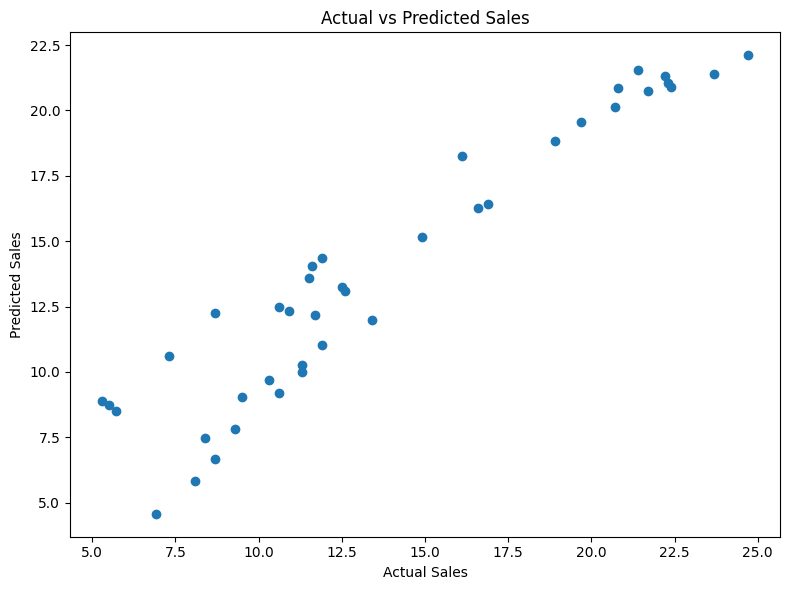

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.tight_layout()
plt.show()



STEP 18: RESIDUAL ANALYSIS

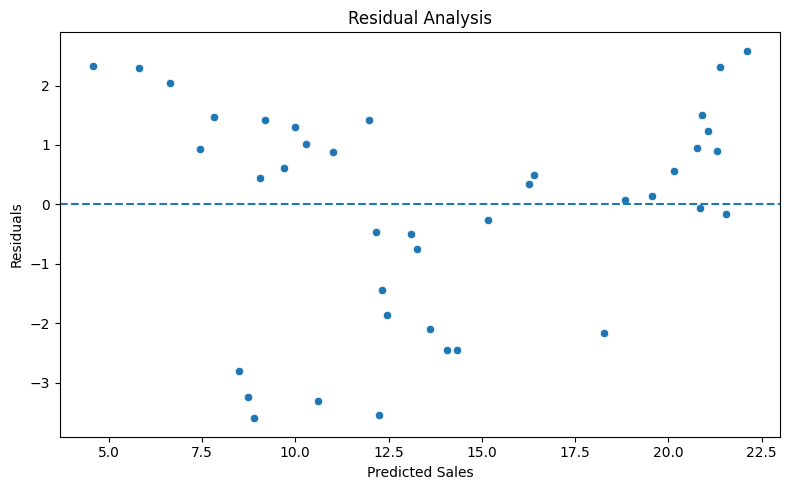

In [ ]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()



STEP 19: FEATURE IMPORTANCE


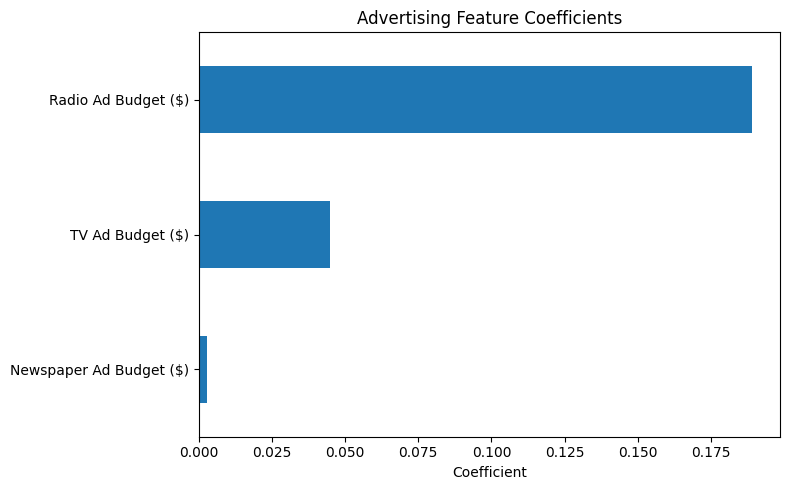

In [ ]:

feature_importance = pd.Series(
    model.coef_,
    index=advertising_columns
)

plt.figure(figsize=(8, 5))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.title("Advertising Feature Coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()



STEP 20: BUSINESS INSIGHTS


In [ ]:

print("\n========== BUSINESS INSIGHTS ==========")

strongest_feature = feature_importance.abs().idxmax()

print(
    "1. The advertising variable with the largest absolute "
    "regression coefficient is:",
    strongest_feature
)

print(
    "2. The model explains approximately",
    round(r2 * 100, 2),
    "% of the variation in sales."
)

print(
    "3. Advertising budgets can be analyzed to understand "
    "their relationship with sales."
)

print(
    "4. Actual and predicted sales can be compared to evaluate "
    "the usefulness of the predictive model."
)

print(
    "5. Correlation and regression analysis help identify "
    "important advertising factors."
)




========== BUSINESS INSIGHTS ==========
1. The advertising variable with the largest absolute regression coefficient is: Radio Ad Budget ($)
2. The model explains approximately 89.94 % of the variation in sales.
3. Advertising budgets can be analyzed to understand their relationship with sales.
4. Actual and predicted sales can be compared to evaluate the usefulness of the predictive model.
5. Correlation and regression analysis help identify important advertising factors.


STEP 21: BUSINESS RECOMMENDATIONS


In [ ]:

print("\n========== BUSINESS RECOMMENDATIONS ==========")

print(
    "1. Use the regression model to estimate expected sales "
    "from advertising budgets."
)

print(
    "2. Monitor advertising channels that show stronger "
    "relationships with sales."
)

print(
    "3. Allocate advertising budgets using historical "
    "performance and predictive analysis."
)

print(
    "4. Periodically retrain the model using new sales data."
)

print(
    "5. Combine predictive analytics with dashboards for "
    "continuous business monitoring."
)




========== BUSINESS RECOMMENDATIONS ==========
1. Use the regression model to estimate expected sales from advertising budgets.
2. Monitor advertising channels that show stronger relationships with sales.
3. Allocate advertising budgets using historical performance and predictive analysis.
4. Periodically retrain the model using new sales data.
5. Combine predictive analytics with dashboards for continuous business monitoring.


QUESTIONS AND ANSWERS


Q1. What are the major stages involved in an end-to-end data
analytics project?

Answer:
The major stages are data collection, data preprocessing,
exploratory data analysis, statistical analysis, visualization,
predictive modeling, model evaluation, interpretation of results,
and communication of business insights.


Q2. Why is data preprocessing considered the foundation of successful
analytics and machine learning?

Answer:
Data preprocessing improves data quality by handling missing values,
duplicates, incorrect data types, and unnecessary variables.
High-quality data helps analytical and machine learning models
produce more reliable results.


Q3. How does Exploratory Data Analysis (EDA) contribute to model
development?

Answer:
EDA helps understand the structure and characteristics of data.
It identifies patterns, relationships, outliers, and possible
problems that can affect model development.


Q4. What factors should be considered while selecting a machine
learning algorithm for a business problem?

Answer:
The type of problem, size and structure of the dataset, target
variable, number of features, interpretability requirements,
computational resources, and required performance should be considered.


Q5. Why is model evaluation essential before deploying a predictive
model?

Answer:
Model evaluation determines how well a model performs on unseen data.
It helps identify errors, overfitting, underfitting, and whether the
model is suitable for practical use.


Q6. Explain how Business Intelligence tools complement machine
learning in data analytics projects.

Answer:
Business Intelligence tools provide dashboards, interactive charts,
and reports for monitoring business performance. Machine learning
provides predictive and analytical capabilities. Together they help
organizations understand current performance and support future
decision-making.


Q7. What challenges are commonly encountered while working with
real-world datasets?

Answer:
Common challenges include missing values, duplicate records,
inconsistent data, outliers, incorrect data types, large datasets,
categorical variables, and noisy information.


Q8. How can analytical insights be converted into actionable business
recommendations?

Answer:
Analytical findings should be connected with business objectives.
Important trends, opportunities, risks, and performance gaps can be
converted into specific actions such as budget allocation, resource
planning, customer targeting, and process improvement.


Q9. Why is effective presentation and data storytelling important
in analytics projects?

Answer:
Effective presentation makes complex analytical findings easier to
understand. Data storytelling connects results with business problems
and helps stakeholders make informed decisions.


Q10. Suggest future improvements or advanced techniques that could
enhance the accuracy and effectiveness of the developed analytics
solution.

Answer:
Future improvements may include collecting more recent data,
feature engineering, cross-validation, hyperparameter tuning,
regularization, ensemble models, advanced regression techniques,
interactive dashboards, and periodic model retraining.
